# Сервис доставки еды

Работаем с данными сервиса доставки еды. Руководство ждёт от продукта роста: необходимо найти инсайты, которые позволят сервису повысить показатель удержания пользователей и улучшить взаимодействие с партнёрами.

Необходимо помочь бизнесу найти точки роста и для этого нужно ответить на следующие вопросы:
- Как ведут себя пользователи? Как наиболее эффективно выстроить работу с ними, чтобы они продолжали пользоваться продуктом?
- Какой путь проходят пользователи в сервисе? Где «проваливаются»?
- Как улучшить взаимодействие с партнёрами-ресторанами?

### Задачи

Анализ данных будет включать:
- изучение пользовательский путь и проанализируете конверсии через воронки;
- сегментирование пользователей с помощью RFM-модели для оценки лояльности и поведения клиентов;
- кластеризация ресторанов методом K-Means, чтобы выделить группы с разными моделями работы и разработать персонализированные маркетинговые стратегии.

Такой подход позволит ближе познакомиться с работой сервиса, выявить узкие места и предложить решения для удержания пользователей и повышения эффективности сотрудничества с ресторанами.


### Данные

Данные включают следующие сведения:
      
- `visitor_uuid` — идентификатор посетителя. Это идентификатор, который присваивается системой любому новому пользователю вне зависимости от того, зарегистрировался он в продукте или нет.
- `user_id` — идентификатор зарегистрированного пользователя. Присваивается посетителю после создания учётной записи: ввода логина, пароля, адреса доставки и контактных данных.
- `device_type` — тип платформы, с которой посетитель зашёл в продукт.
- `city_id` — город, из которого посетитель зашёл в сервис.
- `source` — рекламный источник привлечения посетителя.
- `first_date` — дата первого посещения продукта.
- `visit_id` — уникальный идентификатор сессии.
- `event` — название аналитического события.
- `datetime` — дата и время события.
- `rest_id` — уникальный идентификатор ресторана (заполняется для заказов, карточек ресторанов и блюд).
- `object_id` — уникальный идентификатор блюда (заполняется для заказов и карточек блюд).
- `order_id` — уникальный идентификатор заказа.
- `revenue` — выручка от заказа (в рублях). Это та сумма, которую пользователь видит при оплате.
- `delivery` — стоимость доставки (в рублях).
- `commission` — комиссия, которую сервис берёт с выручки ресторана, в процентах.

    
### План проекта
- Загрузка данных и их предобработка.
- Анализ пользовательского пути новых пользователей.
- RFM сегментация.
- K-Means кластеризация.
- Итоговый вывод и рекомендации.

## 1. Загрузка данных и их предобработка

Начнем с загрузки библиотек и данных. Будем использовать pandas, библиотеки визуализации данных matplotlib и seaborn, библиотеку для работы с массивами и математическими операциями numpy. Также для проведения кластеризации импортируем объект KMeans из библиотеки sklearn.cluster. Данные датасета сохраним в переменную delivery_data. Далее проведем предобработку.

In [ ]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Загружаем библиотеки для работы с массивами и математическими операциями
import numpy as np

# Отключаем предупреждения
import warnings
warnings.filterwarnings('ignore')

# Импортируем объект KMeans из библиотеки sklearn.cluster
from sklearn.cluster import KMeans
# Импортируем нормализатор MinMaxScaler из библиотеки sklearn.preprocessing
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Выгружаем данные в датафрейм
delivery_data = pd.read_csv('https://code.s3.yandex.net/datasets/insides_data.csv', parse_dates=['first_date','datetime'])

Познакомимся с данными датасета. Для начала выведим на экран первые строки и информацию. Затем выведем количество уникальных значений некоторых столбцов и сами уникальные значения, проверим датасет на наличие полных (явных) дубликатов и расчитаем абсолютное и относительное количество пропусков.

In [ ]:
# Выведем первые 3 строки и информации о датасете
display(delivery_data.head(3))
display(delivery_data.info())

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   visitor_uuid  205510 non-null  object        
 1   user_id       205510 non-null  float64       
 2   device_type   205510 non-null  object        
 3   city_id       205510 non-null  int64         
 4   source        205510 non-null  object        
 5   first_date    205510 non-null  datetime64[ns]
 6   visit_id      205510 non-null  int64         
 7   event         205510 non-null  object        
 8   datetime      205510 non-null  datetime64[ns]
 9   rest_id       166915 non-null  object        
 10  object_id     21308 non-null   float64       
 11  order_id      7008 non-null    float64       
 12  revenue       7008 non-null    float64       
 13  delivery      7008 non-null    float64       
 14  commission    21308 non-null   float64       
dtypes: datetime64[ns]

None

In [ ]:
# Отобразим количество уникальных значений в столбцах датафрейма
print('Количество уникальных значений в столбцах датафрейма\n'
      f'Размер датафрейма: {delivery_data.shape[0]}\n')

for column in ['visitor_uuid', 'user_id', 'order_id', 'rest_id', 'object_id']:
    count = delivery_data[column].nunique()
    print(f'Количество уникальных значений в {column}: {count}\n')

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 205510

Количество уникальных значений в visitor_uuid: 8891

Количество уникальных значений в user_id: 8473

Количество уникальных значений в order_id: 4443

Количество уникальных значений в rest_id: 21

Количество уникальных значений в object_id: 603



In [ ]:
# Познакомимся с уникальными значениями в столбцах (ограничим число отображения до 15)
for column in ['visitor_uuid', 'user_id', 'visit_id', 'device_type', 'city_id', 'source', 'event', 'order_id',
               'rest_id', 'object_id', 'revenue', 'delivery', 'commission']:
    unique_vals = delivery_data[column].unique()
    total_count = len(unique_vals)
        # Если уникальных значений больше 15, показываем сокращенный вывод
    if total_count > 20:
        print(f'{column}: {unique_vals[:15]}\n')
    else:
        print(f'{column}: {unique_vals}\n')

visitor_uuid: ['01b5da38-3022-48ff-87c0-5519247fef1b'
 '02920ee1-ae61-4e0c-b457-b24077b52c42'
 '02b9c699-3e27-4ab9-8cc2-d1c9605ecdd6'
 '069679f7-65d4-4391-936d-6a709c02c742'
 '08969d7b-6fa5-48cb-ad45-a915098c8445'
 '0917eb10-d393-4d7e-a911-8721571cb499'
 '0c858e35-00cb-4d8b-ad9f-d19b3b627c2f'
 '0eb15742-903e-450c-9252-063cff29a094'
 '0ff1600a-01bf-4303-a92b-18375e36d347'
 '100a2576-70c1-4533-ae5a-04cb6b98d158'
 '1193a478-a84e-4933-8bfc-6d71ea78b6cb'
 '1a81a60c-00b2-4a4b-9863-2b5c07221f0f'
 '1a8419b0-9908-4a90-91ae-7a19a3ed39a1'
 '15929303-1feb-46dc-be6d-f41b16c0b551'
 '16d3da3e-437f-4d2c-93c1-41b17f712802']

user_id: [567317. 181094. 567068. 566850. 565836. 567210. 210853. 567631.  65498.
 566584. 566991. 342606. 566361. 558195. 567772.]

visit_id: [171481813 171462891 171437453 171400356 171558424 171570030 171404300
 171460594 171515445 171529844 171360113 171352155 171417471 171575178
 171561736]

device_type: ['Desktop' 'Mobile']

city_id: [6 4 2 5 3 1]

source: ['Source_B' 'organi

In [ ]:
# Проверим датасет на наличие полных (явных) дубликатов
duplicates = delivery_data[delivery_data.duplicated(keep=False)]
if duplicates.empty:
    print('Дубликатов нет\n')
else:
    print(f'Найдено дубликатов: {len(duplicates)} строк\n')


Дубликатов нет



In [ ]:
# Отобразим абсолютное и относительное количество пропусков в датасете
missing_stats = pd.DataFrame({
        'Кол-во пропусков': delivery_data.isnull().sum(),
        'Доля пропусков': delivery_data.isnull().mean().round(4)
})
missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
display(missing_stats)

,Кол-во пропусков,Доля пропусков
rest_id,38595,0.1878
object_id,184202,0.8963
order_id,198502,0.9659
revenue,198502,0.9659
delivery,198502,0.9659
commission,184202,0.8963


**Описание данных после предварительного знакомства с датасетом** <br>
Датасет состоит из 15 полей и 205510 записей о пользовательской активностм сервиса доставки еды. Данные охватывают события от авторизации/регистрации до оформления заказов.

Пользовательская база:
- 8891 уникальных посетителей (`visitor_uuid`)
- 8473 зарегистрированных пользователя (`user_id`)
- 4443 уникальных заказа (`order_id`) совершено за рассматриваемый период. <br>

*Важный момент*. У `visitor_uuid` и `user_id` нет пропусков (205510 записей). Это значит, что идентификатор пользователя присваивается (`user_id`) каждому посетителю с первого визита и повторяется во всех его сессиях, скорее всего, независимо от статуса регистрации. Стоит проверить, есть ли пользователи с несколькими `visitor_uuid`. Это поможет обосновать выбор идентификатора для анализа пользовательского пути.

География и устройства:
- Пользователи распределены по 6 городам (`city_id`).
- Используются 2 типа устройств: Desktop и Mobile.

Источники трафика:
- 4 рекламных канала (`source`): Source_A, Source_B, Source_C и organic (органический трафик).

Ресторанная база:
- 21 ресторан-партнёр (`rest_id`) в сервисе.
- 603 уникальных блюда (`object_id`)в меню.

Событийная часть:
- 8 типов событий (`event`), отражающих путь пользователя: от авторизации до покупки. Это позволяет построить полную воронку конверсий.

Качество данных:
- Полные дубликаты отсутствуют.
- Пропуски в данных носят закономерный характер: `rest_id` заполнен только для событий, связанных с ресторанами (81% записей), `object_id` — только для карточек блюд (10% записей, которые связаны с просмотрами, добавлением в корзину, оформлением заказа), `order_id`, `revenue`, `delivery` — только для завершенных заказов (3.4% записей), `commission` — только для заказов (10% записей, которые связаны с просмотрами, добавлением в корзину, оформлением заказа).

Тип данных:
- типы данных соответствуют значениям столбцов, однако знакомство со значениями столбцов показало, что для части из них можно понизить разрядность: `visit_id`, `user_id`, `order_id`, `object_id`, `city_id`, `order_id`, `revenue`, `delivery`, `commission`.



Далее понизим разрядность в указанных полях. Затем проверим, есть ли пользователи (`user_id`) с несколькими идентификаторами посетителя (`visitor_uuid`).


In [ ]:
# Понизим разрядность столбцов с типом данных float64 и int64
columns = ['visit_id', 'user_id', 'order_id', 'object_id', 'city_id', 'order_id', 'revenue', 'delivery', 'commission'
]
for column in columns:
    if pd.api.types.is_float_dtype(delivery_data[column]):
        delivery_data[column] = pd.to_numeric(delivery_data[column], downcast='float')
    elif pd.api.types.is_integer_dtype(delivery_data[column]):
        delivery_data[column] = pd.to_numeric(delivery_data[column], downcast='integer')


In [ ]:
# Выведем информацию о датафрейме, чтобы проверить типы данных
display(delivery_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   visitor_uuid  205510 non-null  object        
 1   user_id       205510 non-null  float32       
 2   device_type   205510 non-null  object        
 3   city_id       205510 non-null  int8          
 4   source        205510 non-null  object        
 5   first_date    205510 non-null  datetime64[ns]
 6   visit_id      205510 non-null  int32         
 7   event         205510 non-null  object        
 8   datetime      205510 non-null  datetime64[ns]
 9   rest_id       166915 non-null  object        
 10  object_id     21308 non-null   float32       
 11  order_id      7008 non-null    float32       
 12  revenue       7008 non-null    float32       
 13  delivery      7008 non-null    float32       
 14  commission    21308 non-null   float32       
dtypes: datetime64[ns]

None

In [ ]:
# Проверяем, есть ли пользователи (user_id) с несколькими  visitor_uuid
# Посчитаем количество и долю таких пользователей
multi_visitor_id_users = (delivery_data.groupby('user_id')['visitor_uuid'].nunique() > 1).sum()
print(f'Количество пользователей с несколькими visitor_uuid: {multi_visitor_id_users}')
print(f"Доля: {multi_visitor_id_users / delivery_data['user_id'].nunique() * 100:.1f}%")

Количество пользователей с несколькими visitor_uuid: 478
Доля: 5.6%


Посмотрим, как выглядят записи пользователя с несколькими visitor_uuid.

In [ ]:
# Посчитаем количество visitor_uuid для каждого пользователя
multi_visitor_id = delivery_data.groupby('user_id')['visitor_uuid'].nunique().reset_index()
# Выведем не экран нескольких пользователей, у которых больше одного идентификатора посетителя (visitor_uuid)
display((multi_visitor_id[multi_visitor_id['visitor_uuid'] > 1]).head())

,user_id,visitor_uuid
3,5506.0,2
21,14504.0,2
36,23683.0,3
42,28514.0,2
45,29764.0,3


In [ ]:
# Выведем на экран записи посетителя с user_id 5506.0, у которого 2 идентификатора посетителя
display(delivery_data[delivery_data['user_id'] == 5506.0])

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
10649,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,login,2021-05-04 11:39:23,NaN,NaN,NaN,NaN,NaN,NaN
11850,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,authorization,2021-05-04 11:39:07,NaN,NaN,NaN,NaN,NaN,NaN
11851,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,reg_page,2021-05-04 11:39:16,NaN,NaN,NaN,NaN,NaN,NaN
11852,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,confirm_phone,2021-05-04 11:39:19,NaN,NaN,NaN,NaN,NaN,NaN
11853,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,add_to_cart,2021-05-04 11:39:31,8d9fb9d5992f400eaf02660973a66adf,27825.0,595119.0,2380.0,12.300000,0.05
11854,79ad695c-34d9-49a1-b10a-126b2104a14d,5506.0,Desktop,5,Source_C,2021-05-04,172284649,order,2021-05-04 11:39:34,8d9fb9d5992f400eaf02660973a66adf,27825.0,595119.0,2380.0,12.300000,0.05
97309,f7330b9c-4e48-48b4-864c-0f9a1d6b8831,5506.0,Desktop,5,Source_C,2021-05-31,180172157,authorization,2021-05-31 00:48:58,NaN,NaN,NaN,NaN,NaN,NaN
97310,f7330b9c-4e48-48b4-864c-0f9a1d6b8831,5506.0,Desktop,5,Source_C,2021-05-31,180172157,reg_page,2021-05-31 00:49:19,NaN,NaN,NaN,NaN,NaN,NaN
97311,f7330b9c-4e48-48b4-864c-0f9a1d6b8831,5506.0,Desktop,5,Source_C,2021-05-31,180172157,confirm_phone,2021-05-31 00:49:22,NaN,NaN,NaN,NaN,NaN,NaN
97312,f7330b9c-4e48-48b4-864c-0f9a1d6b8831,5506.0,Desktop,5,Source_C,2021-05-31,180172157,login,2021-05-31 00:49:26,NaN,NaN,NaN,NaN,NaN,NaN


**Промежуточный вывод** <br>

Данные сервиса (205510 записей) пригодны для анализа: нет полных дубликатов, пропуски закономерны и соответствуют бизнес-логике. Пользовательская база насчитывает 8891 посетителей, но только 4443 завершенных заказов. Структура данных позволяет построить полную воронку (8 событий), сегментировать пользователей по географии (6 городов), устройствам (2 типа) и источникам трафика (4 канала). Ресторанная сеть включает 21 партнера с 603 блюдами. Выполнено понижение разрядности для оптимизации памяти.

Поскольку 478 пользователей (5.6%) имеют несколько идентификаторов посетителя (`visitor_uuid`), в качестве основного идентификатора пользователя в дальнейшем анализе будет выбран `user_id`, который остается стабильным на протяжении всего взаимодействия человека с сервисом.

Данные готовы к построению воронок, RFM-сегментации и кластеризации ресторанов.

---

## 2. Анализ пользовательского пути

Маркетологи заметили, что рекламный бюджет остаётся на прежнем уровне, но количество заказов снижается. При этом скачивания и установки приложения не падают — продукт по-прежнему привлекает внимание. Возникает ощущение, что пользователи теряются на каком-то из этапов взаимодействия с сервисом. Также наблюдается рост доли заказов, совершённых с десктопной версии, по сравнению с мобильной.

Разработчики отмечают, что последние обновления мобильного приложения не должны были повлиять на каталог блюд, процесс их выбора или оплату доставки, так как изменения касались только нового алгоритма подтверждения телефона и адреса.

Чтобы разобраться в ситуации, проведём анализ пользовательского пути с помощью воронок. Сначала изучим общую воронку для новых пользователей, а затем сравним поведение пользователей мобильной и десктопной версий.

**Задача 2.1. Строим классическую и step‑by‑step воронку**

На этом этапе нам предстоит:

- определить, из каких шагов состоит путь пользователя;
- построить две воронки: классическую (доля от первого шага) и step‑by‑step (конверсия от предыдущего этапа);
- выявить этапы, на которых теряется наибольшая доля новых пользователей.
    

В качестве основы возьмём следующий путь пользователя к оформлению заказа: <br>
`authorization` — авторизация пользователя — запуск приложения.<br>
`main_page` — загрузка основной страницы приложения.<br>
`reg_page` — переход на страницу регистрации.<br>
`confirm_phone` — подтверждение телефона (окончание процесса регистрации).<br>
`object_page` — страница блюда.<br>
`add_to_cart` — переход в корзину.<br>
`order` — оформление заказа. <br>

In [ ]:
# Задаём порядок шагов воронки пользовательского пути
funnel_steps = ['authorization', 'main_page', 'reg_page', 'confirm_phone', 'object_page', 'add_to_cart', 'order']

# Оставляем только события, входящие в воронку
funnel_data = delivery_data[delivery_data['event'].isin(funnel_steps)]

# Считаем уникальных пользователей на каждом шаге и сортируем по порядку воронки
funnel_data = funnel_data.groupby('event')['user_id'].nunique().reindex(funnel_steps).reset_index()
funnel_data = funnel_data.rename(columns={'user_id': 'users_n'})

# Конверсия от первого шага
funnel_data['conversion_%'] = (funnel_data['users_n'] / funnel_data['users_n'].iloc[0] * 100).round(1)

# Конверсия от предыдущего шага (step-by-step)
funnel_data['conversion_from_previous_step_%'] = (funnel_data['users_n'] / funnel_data['users_n'].shift(1) * 100).round(1)

# Выводим итоговую таблицу воронки
funnel_data

,event,users_n,conversion_%,conversion_from_previous_step_%
0,authorization,7410,100.0,NaN
1,main_page,6537,88.2,88.2
2,reg_page,5417,73.1,82.9
3,confirm_phone,4190,56.5,77.3
4,object_page,3453,46.6,82.4
5,add_to_cart,2899,39.1,84.0
6,order,2416,32.6,83.3


Теперь визуализируем полученную таблицу с помощью столбчатых диаграмм.

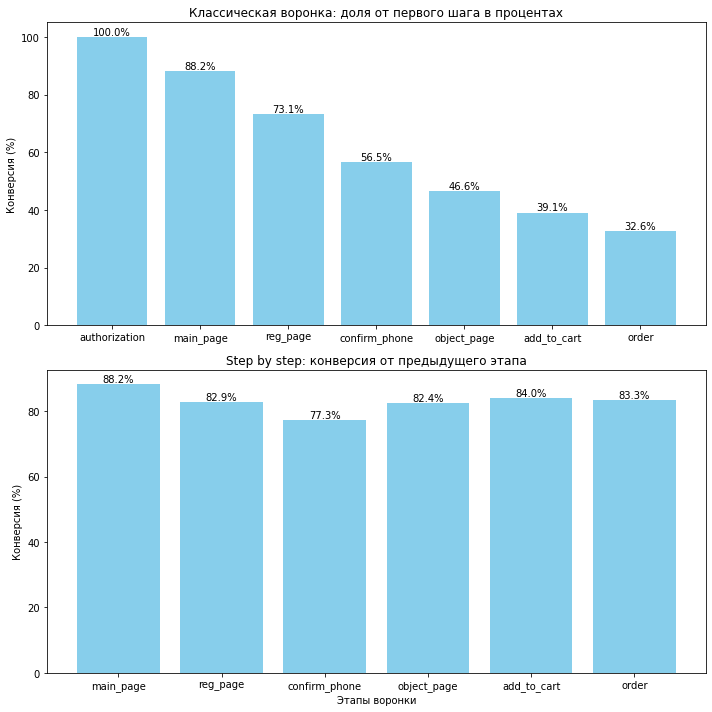

In [ ]:
# Строим две столбчатые диаграммы
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Классическая воронка
axes[0].bar(funnel_data['event'], funnel_data['conversion_%'], color='skyblue')
axes[0].set_title('Классическая воронка: доля от первого шага в процентах')
axes[0].set_ylabel('Конверсия (%)')
# Добавляем подписи значений на столбцы
for x, y in zip(funnel_data['event'], funnel_data['conversion_%']):
    if pd.notna(y):
        axes[0].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

# Step by step воронка
axes[1].bar(funnel_data['event'], funnel_data['conversion_from_previous_step_%'], color='skyblue')
axes[1].set_title('Step by step: конверсия от предыдущего этапа')
axes[1].set_ylabel('Конверсия (%)')
axes[1].set_xlabel('Этапы воронки')
# Добавляем подписи значений на столбцы
for x, y in zip(funnel_data['event'], funnel_data['conversion_from_previous_step_%']):
    if pd.notna(y):
        axes[1].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

По классической воронке видно, что на втором этапе - загрузка основной страницы приложения - остается 88.2% пользователей, то есть примерно каждый восьмой не проходит дальше авторизации. Только 73.1% переходят на страницу регистрации, что означает, что около четверти посетителей не доходят до этого этапа. Чуть больше половины (56.5%) подтверждают номер телефона, 39.1% пользователей добавляют товар в корзину, и 32.6% оформляют заказ. Стоит отметить, что воронка отражает факт наличия события у пользователя, а не строгую последовательность шагов внутри одной сессии.

Воронка step-by-step показала существенную потерю между шагами `reg_page` и `confirm_phone` — конверсия составила 77.3%, то есть теряется 22.6% пользователей на этапе подтверждения телефона. На остальных этапах, кроме перехода от `authorization` к `main_page`, конверсия держится на уровне 82–84%, что соответствует потере 16–18% пользователей между соседними шагами.

**Задача 2.2 Сравним пользовательский путь в двух версиях приложения**

Чтобы понять, как по‑разному ведут себя пользователи на разных платформах, построим и визуализируем две step‑by‑step воронки: одну — для пользователей мобильной версии, вторую — для пользователей десктопной версии.

После этого сравним полученные результаты между собой и проанализируем, есть ли значимые различия в поведении пользователей в зависимости от типа приложения. На основе этого сравнения сформулируем небольшой промежуточный вывод.

In [ ]:
# Посчитаем step‑by‑step воронки для двух платформ
# Словарь для хранения результатов по платформам
funnel_results = {}

# Создадим цикл, где будем считать уникальных пользователей на каждом шаге по платформам
for platform in delivery_data['device_type'].unique():
    # Фильтруем данные по платформе
    platform_data = delivery_data[delivery_data['device_type'] == platform]

    # Оставляем только нужные шаги и считаем уникальных пользователей
    funnel_counts = (
        platform_data[platform_data['event'].isin(funnel_steps)]
        .groupby('event')['user_id']
        .nunique()
        .reindex(funnel_steps)
    )

    # Считаем step-by-step конверсию и сохраняем в словарь
    funnel_results[platform] = (funnel_counts / funnel_counts.shift(1) * 100).round(1)

# Собираем финальный датафрейм
funnel_compare = pd.DataFrame({
    'step': funnel_steps[1:],
    'mobile': funnel_results['Mobile'].values[1:],
    'desktop': funnel_results['Desktop'].values[1:]
})

# Выводим итоговую таблицу
funnel_compare


,step,mobile,desktop
0,main_page,83.3,91.1
1,reg_page,88.4,79.4
2,confirm_phone,55.1,90.2
3,object_page,72.5,85.8
4,add_to_cart,86.7,82.9
5,order,85.8,82.3


Визуализируем полученные данные при помощи столбчатой диаграммы.

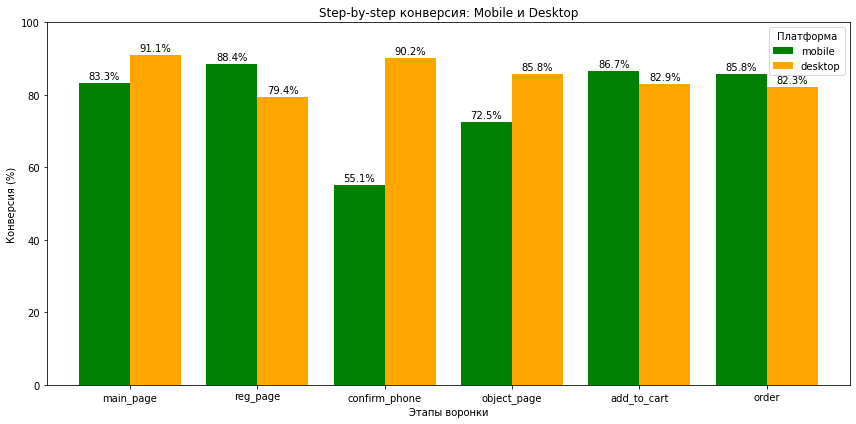

In [ ]:
# Подготавливаем данные
funnel_plot = funnel_compare.set_index('step')

# Строим график
ax = funnel_plot.plot(kind='bar', figsize=(12, 6), color=['green', 'orange'], width=0.8)

# Добавляем подписи значений на столбцы
for p in ax.patches:
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.,
        height + 0.5,
        f'{height:g}%',
        ha="center",
        va="bottom"
        )

# Настройки графика
plt.title('Step‑by‑step конверсия: Mobile и Desktop')
plt.ylabel('Конверсия (%)')
plt.xlabel('Этапы воронки')
plt.legend(title='Платформа')
plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


Сравним step‑by‑step воронки пользователей мобильной и десктопной версии.

На шаге перехода к главной странице (`main_page`) конверсия у десктопных пользователей составляет 91.1%, что заметно выше, чем у мобильных (83.3%). Это означает, что на мобильных устройствах теряется примерно каждый шестой пользователь после авторизации, тогда как на десктопе — только каждый одиннадцатый.

Наиболее критичное различие наблюдается на этапе подтверждения норера телефона (`confirm_phone`): если на десктопе конверсия держится на высоком уровне 90.2%, то на мобильных устройствах она резко падает до 55.1%. Это говорит о том, что на мобильной платформе теряется почти половина пользователей, дошедших до регистрации. Вероятно, есть проблема с новым алгоритмом подтверждения телефона.

На следуюзем шаге - переход на страница блюда (`object_page`) - также заметна разница в конверсии пользователей: для мобильных устройств конверсия с предыдущего шага составила 72.5%, для десктопа - 85.8%. Опять же, по всей видимости, мобильные пользователи сталкиваются с трудностями на этапах после регистрации или, даже если посльзователь прошел регистрацию, проблемы на этом этапе приводят к потери части пользователей на этом шаге.

На последующих шагах (`add_to_cart`, `order`) конверсия стабилизируется и держится в диапазоне 72–86% на обеих платформах, причём мобильные пользователи даже немного опережают десктопных на финальных шагах (85.8% мобильные, 82.3% десктопные на этапе заказа). Это указывает на то, что если пользователь успешно прошёл регистрацию на мобильном устройстве, его дальнейшее поведение не уступает десктопному, а на последних этапах даже эффективнее.

**Промежуточный вывод:**

Классическая воронка показывает последовательное снижение доли пользователей на каждом шаге. Наиболее большая потеря (22.6%) происходит при подтверждении телефона, что указывает на проблемный этап в пользовательском пути.

Сравнение платформ выявило существенные различия: десктопные пользователи стабильно проходят первые этапы (91.1% против 83.3% на `main_page`), тогда как мобильные резко теряются на `confirm_phone` (55.1% против 90.2% у десктопа) и `object_page` (72.5% против 85.8%). При этом те, кто успешно преодолевает эти этапы на мобильных устройствах, демонстрируют конверсию в заказ даже выше десктопных (85.8% мобильные и 82.3% десктопные).

Таким образом, ключевая проблема сосредоточена в мобильной версии на этапах подтверждения телефона и перехода к странице блюда, что согласуется с информацией о внесенных изменениях в алгоритм подтверждения.

---

## 3. RFM сегментация

У сервиса доставки еды не такое высокое удержание пользователей: в первый день возвращается около 14% посетителей, а на седьмой день и того меньше — около 4–5%. Маркетологи хотят запустить несколько рекламных кампаний, направленных на удержание платящих пользователей и их возврат в сервис, если они давно не совершали заказы.

Для этого необходимо сегментировать пользователей на различные поведенческие сегменты с помощью RFM-сегментации по трём показателям:
- **давность** (Recency),
- **частота покупок** (Frequency),
- **сумма трат** (Monetary).



**Задача 3.1.  Для каждого покупателя посчитаем давность, частоту покупок и сумму трат:**
- количество дней с последней покупки — давность (R);
- частоту покупок (F);
- стоимость всех покупок — сумму трат (M).
    
В качестве даты анализа установим: **03 июля 2021 года**. После этого построим три гистограммы и проанализируем их.

In [ ]:
# Подготовим данные: оставим только записи с заказом.
delivery_orders = delivery_data[delivery_data['event'] == 'order']

# Рассчитываем количество дней с покупки до даты анализа
delivery_orders['order_recency'] = pd.to_datetime('2021-07-03') - delivery_orders['datetime']

# Группируем данные для каждого пользователя и рассчитываем данные для RFM-анализа
delivery_rfm = delivery_orders.groupby('user_id').agg(
    recency = ('order_recency', lambda x: x.min().days),
    frequency = ('datetime', 'count'),
    monetary = ('revenue', 'sum')
).reset_index()


# Выводим полученную таблицу
delivery_rfm.head()

,user_id,recency,frequency,monetary
0,5506.0,32,2,3752.000000
1,6291.0,57,1,1750.000000
2,6820.0,41,1,1260.140015
3,11062.0,57,1,3785.600098
4,13254.0,54,1,553.000000


Построим гистограммы, чтобы визуализировать распределение по давности, частоте покупок и сумме трат каждого пользователя.

Показатель давности (количество дней с последней покупки) имеет распределение, близкое к равномерному, в диапазоне от 1 до 63. Это означает, что с примерно равной вероятностью в данных можно встретить пользователей, которые сделали заказ как 2, так и 30 или 60 дней назад.

Частота покупок распределена неравномерно с сильным смещением к более низким значениям. Значения варьируются от 1 до 12, при этом преобладают пользователи с 1–3 заказами.

Распределение суммы трат также смещено влево — резко преобладают пользователи с недорогими заказами (до 10 000).

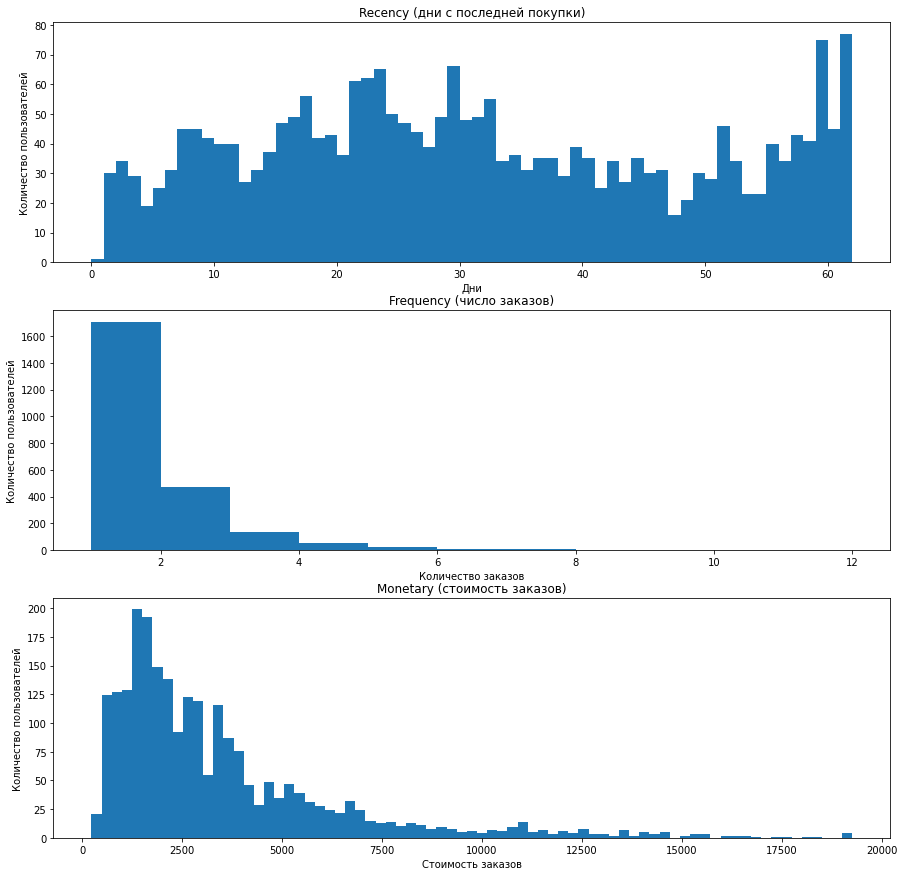

In [ ]:
# Строим три гистограммы
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

# Давность
axes[0].hist(delivery_rfm['recency'], bins=np.arange(0, delivery_rfm['recency'].max()+1, 1))
axes[0].set_title('Recency (дни с последней покупки)')
axes[0].set_xlabel('Дни')
axes[0].set_ylabel('Количество пользователей')

# Частота
axes[1].hist(delivery_rfm['frequency'], bins=np.arange(1, delivery_rfm['frequency'].max()+1, 1))
axes[1].set_title('Frequency (число заказов)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество пользователей')

# Фильтруем выбросы по monetary (оставляем значения ниже 99-го процентиля)
monetary_filtered = delivery_rfm['monetary'][delivery_rfm['monetary'] < delivery_rfm['monetary'].quantile(0.99)]

# Сумма всех заказов
axes[2].hist(monetary_filtered, bins=75)
axes[2].set_title('Monetary (стоимость заказов)')
axes[2].set_xlabel('Стоимость заказов')
axes[2].set_ylabel('Количество пользователей')

plt.show()

**Задача 3.2.** Выделим **RFM-сегменты** и изучим распределение пользователей по ним.
    
Применим следующие подходы к выделению RFM сегментов:
- **Recency** — разделим на три равные группы.
- **Frequency** —  разделим на три группы:
    - пользователи с 1 заказом (F-сегмент с небольшим количеством заказов);
    - пользователи с 2 заказами (F-сегмент со средним количеством заказов);
    - пользователи с 3 и более заказами (F-сегмент с большим количеством заказов).
- **Monetary** — разделим на три группы по 33-му и 66-му перцентилям.
    
После этого посчитаем количество покупателей в каждом сегменте, сделаем промежуточные выводы и напишем рекомендации.

In [ ]:
# Выделим RFM-сигменты
# Определяем группу пользователя по количеству дней с момента последней покупки
delivery_rfm['r'] = pd.cut(delivery_rfm['recency'], bins=3, labels=[3,2,1])
# Определяем группу пользователя по количеству покупок
delivery_rfm['f'] = delivery_rfm['frequency'].apply(lambda x: 3 if x >= 3 else (2 if x == 2 else 1))
# Определяем группу пользователя по сумме стоимости заказов
delivery_rfm['m'] = pd.qcut(delivery_rfm['monetary'], q=3, labels=[1,2,3])

# Находим групповой RFM-индекс
delivery_rfm[['r','f','m']] = delivery_rfm[['r','f','m']].astype('str')
delivery_rfm['rfm_group'] = delivery_rfm['r'] + delivery_rfm['f'] + delivery_rfm['m']

# Выводим первые строки таблицы:
delivery_rfm.head(30)


,user_id,recency,frequency,monetary,r,f,m,rfm_group
0,5506.0,32,2,3752.000000,2,2,3,223
1,6291.0,57,1,1750.000000,1,1,1,111
2,6820.0,41,1,1260.140015,2,1,1,211
3,11062.0,57,1,3785.600098,1,1,3,113
4,13254.0,54,1,553.000000,1,1,1,111
5,19806.0,10,1,1680.000000,3,1,1,311
6,22712.0,3,1,1120.000000,3,1,1,311
7,23683.0,32,1,3472.000000,2,1,2,212
8,26648.0,21,1,2240.000000,2,1,2,212
9,28117.0,21,2,11319.755859,2,2,3,223


Подсчитаем количество пользователей в каждом RFM-сигменте.

In [ ]:
# Группируем данные по сегментам и считаем их размер
rfm_group = delivery_rfm.groupby('rfm_group')['user_id'].nunique().reset_index(name='users_count')

# Считаем долю пользователей в каждом сегменте
rfm_group['user_share'] = rfm_group['users_count'] / rfm_group['users_count'].sum()

# Выводим результат
print(rfm_group.sort_values(by='users_count', ascending=False))

   rfm_group  users_count  user_share
8        211          281    0.116308
0        111          247    0.102235
17       311          246    0.101821
9        212          237    0.098096
1        112          216    0.089404
18       312          186    0.076987
10       213          122    0.050497
13       223          115    0.047599
16       233          102    0.042219
19       313           99    0.040977
22       323           88    0.036424
5        123           85    0.035182
2        113           75    0.031043
24       333           68    0.028146
12       222           59    0.024421
21       322           48    0.019868
4        122           45    0.018626
7        133           41    0.016970
3        121           16    0.006623
15       232            9    0.003725
20       321            9    0.003725
11       221            8    0.003311
6        132            8    0.003311
23       332            5    0.002070
14       231            1    0.000414


**Анализ RFM-сегментов:**

Результаты показывают, что самые многочисленные сегменты - это 211 (11.6%), 111 (10.2%) и 311 (10.2%). Это пользователи с низкой частотой покупок (одна покупка) и невысокими тратами, при этом 211 и 311 имеют среднюю и высокую давность последнего заказа. Таким образом, основная часть аудитории (около трети) совершает редкие недорогие покупки и слабо вовлечена в сервис.

Также относительно заметно представлены сегменты 212 (9.8%), 112 (8.9%) и 312 (7.7%) - пользователи со средними показателями по одному-двум из критериев. В совокупности это примерно 25% аудитории сервиса.

Сегмент самой лояльной группы пользователей (333) составляет 2.8% покупателей - пользователи с недавними, частыми и дорогими заказами.

Наименее представлены сегменты с комбинациями: 231, 332, 132, 221, 232, 321 (менее 1% каждый). Это пользователи с редкими паттернами поведения.

**Промежуточные выводы и рекомендации:**
- Почти половина пользователей совершили всего одну покупку. Среди них есть те, кто заказывал недавно (сегменты 311, 312, 313) - им нужно поддерживать интерес и стимулировать к повторным заказам. А также те, чей последний заказ был относительно давно (сегменты 211, 212) - их можно пробовать возвращать специальными предложениями.

- Группа клиентов, у которых давно не было покупок, включает сегменты 111, 112, 113, 121, 122, 123, 133. Среди них есть пользователи, которые могут принести прибыль при правильном подходе. Для их возврата стоит разработать персональные предложения и напоминания.

- Самые ценные клиенты - сегмент 333 (2.8%). Это пользователи с недавними, частыми и дорогими заказами. Их важно удерживать с помощью программ лояльности и эксклюзивных предложений.

**Анализ RFM-сегментов:**
По результатам сегментации получено 27 RFM-групп. Проанализируем сегменты пользователей, сгруппировав их частоте и давности покупок.

**Пользователи с одной покупкой (frequency = 1)** <br>

Это самая многочисленная категория пользователей.<br>
*Недавняя покупка (recency = 3)*: 311 (10.2%), 312 (7.7%), 313 (4.1%)<br>
Совокупно - около 22% аудитории. Это новые или недавно привлеченные клиенты. Они уже проявили интерес к сервису, но пока не стали постоянными.<br>
*Покупка средней давности (recency = 2)*: 211 (11.6%), 212 (9.8%), 213 (5.0%)<br>
Совокупно - около 26% аудитории (самая крупная поведенческая группа).<br>
Это пользователи, которые попробовали сервис, но не вернулись в ближайший период (в течение 40 дней).<br>
*Давняя покупка (recency = 1)*: 111 (10.2%), 112 (8.9%), 113 (3.1%)<br>
Совокупно - около 22% аудитории.<br>
Это пользователи с одной и давно совершенной покупкой (больше 40 дней).<br>

Таким образом, пользователи с одной покупкой составляют около 70% всей аудитории, что говорит редкости повторяемости заказов и, соответственно, высоком потенциале роста за счёт удержания.

**Клиенты с  двумя покупками (frequency = 2)**

Эта группа пользователей занимает вторую позицию по количеству. <br>
*Недавняя активность:* 321 (0.4%), 322 (2.0%), 323 (3.6%) <br>
*Средняя давность:* 221 (0.3%), 222 (2.4%), 223 (4.8%) <br>
*Давняя активность:* 121 (0.7%), 122 (1.9%), 123 (3.5%) <br>

Совокупная доля сегментов с двумя покупками (средняя частота) - около 20%.<br>

Это пользователи, которые уже совершали повторные покупки, но их вовлеченность неочевидна.


**Лояльные клиенты (frequency = 3)**

*Недавние и дорогие:* 333 (2.8%) <br>
*Недавние, но менее дорогие:* 332 (0.2%) <br>
*Средняя давность:* 231 (0.04%), 232 (0.4%), 233 (4.2%) <br>
*Давняя активность:* 132 (0.3%), 133 (1.7%)<br>
Совокупно сегменты с высокой частотой составляют около 9–10% аудитории.<br>
Это наиболее ценная категория клиентов, формирующая значительную долю выручки.<br>

**Промежуточные выводы и рекомендации:** <br>
*Пользователи с одной покупкой* <br>
Около 70% пользователей совершили только одну покупку. Это ключевая зона роста бизнеса, поскольку повышение доли повторных заказов может существенно повлиять на выручку. Недавно привлеченные клиенты (311–313) еще сохраняют интерес к сервису, поэтому для них важно стимулировать вторую покупку через персональные предложения. Сегменты 211–213 (клиенты которые относительно давно делали заказ) представляют наибольшую по численности группу с интересом - здесь могут дать эффект реактивационные кампании (промокоды с ограниченным сроком действия, бонус за возвращение (скидка для повторного заказа), напоминание о продукте). Пользователи из сегментов 111–113 с давней единственной покупкой требуют более осторожного подхода: стоит оценить их потенциальную рентабельность перед запуском маркетинговой компании.

*Пользователи со средней частотой (две покупки)* <br>
Пользователи с двумя покупками составляют около 20% от общего числа и уже демонстрируют возвращаемость в продукт. Однако для сегментов 121, 122, 123 повторные покупки были сделаны уже относительно давно. Тем не менее пользователей этой группы (особенно сегменты с недавними покупками 321, 322, 323) проще довести до статуса устойчиво лояльных, чем возвращать полностью ушедших клиентов. Для этой группы можно также предложить персональные предложения, внедрять механики накопительных бонусов.

*Лояльные пользователи* <br>
Сегменты с высокой частотой покупок формируют около 10% аудитории, при этом наиболее ценный сегмент 333 составляет 2.8% пользователей. Несмотря на небольшую численность, именно эта группа обеспечивает максимальную ценность для бизнеса. Основной акцент должен быть сделан на удержании таких клиентов и предотвращении снижения их активности через программы лояльности и эксклюзивные предложения.



---

## 4. K-Means кластеризация

Чтобы лучше понимать поведение ресторанов и предлагать им персонализированные условия сотрудничества, а также создавать персонализированные предложения для пользователей, маркетологи запросили кластеризацию ресторанов по следующим параметрам:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

С помощью метода K-Means разделим рестораны на кластеры, отражающие различные модели работы и целевые сегменты. Это позволяет выделить группы ресторанов с похожими характеристиками и разрабатывать для них эффективные маркетинговые стратегии.

**Задача 4.1.** Подготовим данные для кластеризации и для каждого ресторана подсчитайте:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

Будем работать с датафреймом delivery_orders, в котором хранятся записи о заказах.

In [ ]:
#  Для каждого ресторана рассчитаем общее количество заказов, их среднюю стоимость, общее число заказанных уникальных блюд
delivery_rests = delivery_orders.groupby('rest_id').agg(
    order_counts = ('order_id', 'count'),
    avg_revenue = ('revenue', 'mean'),
    object_counts = ('object_id', 'nunique')
).reset_index()

# Веведим несколько строк полученной таблицы
delivery_rests

,rest_id,order_counts,avg_revenue,object_counts
0,1be5a933aab34fbab594bebba48e976e,144,2260.180176,28
1,1d6bb74687104fa1953924c9684fe624,108,2959.256592,19
2,2c6095730b514c189ee41c65f03febc3,8,1673.000000,4
3,3247a3b5f9494812a3c1a73c5b61f004,33,2777.209717,4
4,39b7eab4f4704ed2886fafe171489960,33,2011.269653,5
5,43e40bacafe8409bb5592877a42d737e,43,3313.064209,6
6,4a693ca500b44ba499f92a724aec5f17,107,2989.588867,12
7,4b9cde3378c447ed81c2c6d4854d4f7e,7,2544.000000,5
8,55d4027ac83e438f9f893892f6903409,1001,2674.652344,75
9,55d6470712ee48e98509478ad6aa18ee,5,4754.399902,2


**Задача 4.2.** Нормализуем данные и найдем оптимальное количество кластеров, использовав метод `.inertia_`. Построим график зависимости инерции от числа кластеров (метод «локтя») и предположим оптимальное количество кластеров.

Нормализуем данные, так как показатели имеют разный диапазон: количество заказов может варьироваться от единиц до сотен, количество уникальных блюд - от единиц до десятков,  средняя выручка - в тысячах. Для нормализации будем использовать инструмент MinMaxScaler из библиотеки sklearn: он приводит все признаки к единому масштабу в диапазоне от 0 до 1.

In [ ]:
# Выбираем признаки для нормализации
features = ['order_counts', 'avg_revenue', 'object_counts']

# Создаём нормализатор для приведения данных к диапазону от 0 до 1
scaler = MinMaxScaler()

# Нормализуем признаки
delivery_rests_scaled = scaler.fit_transform(delivery_rests[features])

# Преобразуем обратно в DataFrame (для удобства)
delivery_rests_scaled = pd.DataFrame(delivery_rests_scaled, columns=features)

# Выводим результат
delivery_rests_scaled.head()

,order_counts,avg_revenue,object_counts
0,0.116415,0.231759,0.300000
1,0.086265,0.447081,0.200000
2,0.002513,0.050903,0.033333
3,0.023451,0.391009,0.033333
4,0.023451,0.155093,0.044444


Теперь построим график зависимости инерции от числа кластеров (метод «локтя»).

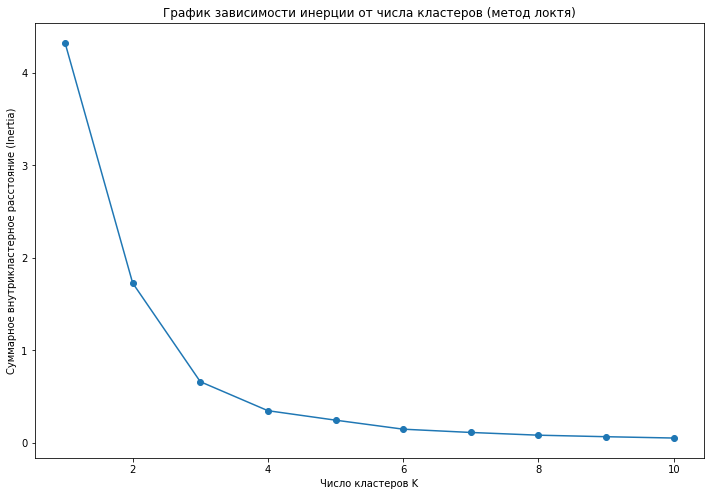

In [ ]:
# Создаём массив, в котором будем хранить значения inertia для разбиения с разным числом кластеров
i = []

# Задаем диапазон количества кластеров
min_k = 1
max_k = 10

# Настроим размер графика
plt.figure(figsize=(12, 8))

# Перебираем разное количество кластеров
for k in range(min_k, max_k + 1):
   km = KMeans(n_clusters=k)
   km.fit(delivery_rests_scaled)
   i.append(km.inertia_)

# Строим график зависимости инерции от количества кластеров
plt.plot(range(min_k, max_k + 1), i, marker='o')
plt.xlabel('Число кластеров K')
plt.ylabel('Суммарное внутрикластерное расстояние (Inertia)')
plt.title('График зависимости инерции от числа кластеров (метод локтя)')
plt.show()

На графике изображена кривая суммарного внутрикластерного расстояния (инерции) для каждого количества кластеров. Метод "локтя" позволяет определить оптимальное число кластеров: необходимо найти точку, после которой снижение инерции замедляется и становится плавным. В данном случае оптимальное число кластеров - 3.

Для определения оптимального числа кластеров дополнительно воспользуемся методом иерархической кластеризации (дендрограмма).

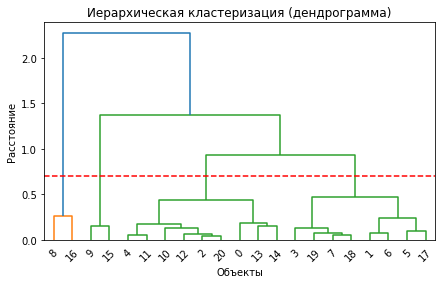

In [ ]:
# Создадим таблицу связей:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(delivery_rests_scaled, method = 'ward')

# Визуализируем таблицу связей:
plt.figure(figsize=(7, 4))
dendrogram(linked, orientation='top')

plt.axhline(y=0.7, color='r', linestyle='--')
plt.title("Иерархическая кластеризация (дендрограмма)")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")

plt.show()

Опираясь на дендрограмму, будем проводить кластеризацию с 4 кластерами.

**Задача 4.3.** Проведем кластеризацию, проанализируем полученные результаты и рассчитаем средние значения по каждому кластеру.
    
После этого визуализируем результаты, чтобы проследить зависимость признаков друг от друга. Построим две визуализации, на которые нанесите все кластеры:
- средний чек в зависимости от количества заказов;
- количество блюд в зависимости от количества заказов.

После этого опишем каждый кластер в промежуточном выводе.

Сначала проведем кластеризацию и рассчитаем средние значения по каждому кластеру. Для интерпретации средних переведем центроиды в исходные единицы.

In [ ]:
# Нормализуем признаки для кластеризации
scaler = MinMaxScaler()
rests_scaled = scaler.fit_transform(delivery_rests[features])

# Кластеризация ресторанов методом K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(rests_scaled)

# Получаем центроиды в исходных единицах (обратное преобразование)
centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

# Создаём DataFrame с центроидами для удобного анализа
centroids_df = pd.DataFrame(
    centroids_original,
    columns=['Количество заказов', 'Средняя выручка', 'Количество уникальных блюд'],
    index=[f'Кластер {i+1}' for i in range(4)]
)

# Выводим таблицу
centroids_df

,Количество заказов,Средняя выручка,Количество уникальных блюд
Кластер 1,71.727273,1931.617487,8.636364
Кластер 2,1100.000000,2498.828735,83.000000
Кластер 3,65.333333,3024.750977,9.166667
Кластер 4,84.000000,4657.770264,2.500000


Мы получили таблицу со средними значениями признаков.

Кластер 1: непопулярные бюджетные рестораны с узким ассортиментом <br>
Количество заказов: 72 | Средняя выручка: 1932| Количество уникальных блюд: 9

Кластер 2: популярные бюджетные рестораны с широким ассортиментом <br>
Количество заказов: 1100 | Средняя выручка: 2499| Количество уникальных блюд: 83 <br>

Кластер 3: непопулярные рестораны со средним чеком выше среднего <br>
Количество заказов: 65 | Средняя выручка: 3025 | Количество уникальных блюд: 9

Кластер 4: непопулярные дорогие рестораны с очень узким ассортиментом <br>
Количество заказов: 84 | Средняя выручка: 4658 | Количество уникальных блюд: 2–3


Далее построим две визуализации (диаграммы рассеяния): средний чек в зависимости от количества заказов; количество блюд в зависимости от количества заказов.

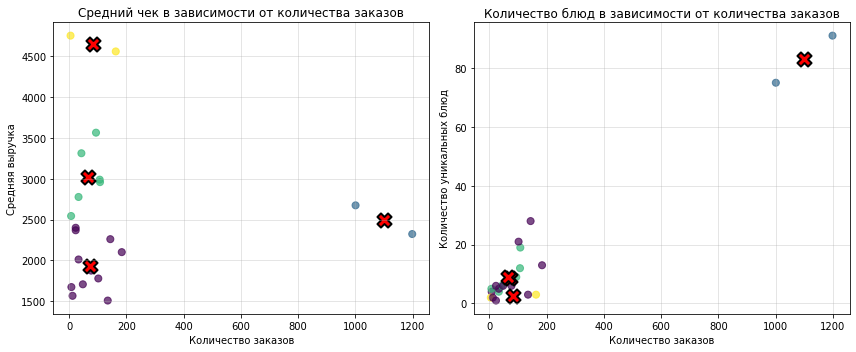

In [ ]:
# Добавляем метки кластеров в исходный DataFrame с данными
delivery_rests['cluster'] = labels

# Создаем 2 графика рядом
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Создаем график: средний чек в зависимости от количества заказов
axes[0].scatter(
    delivery_rests['order_counts'],
    delivery_rests['avg_revenue'],
    c=delivery_rests['cluster'],
    cmap='viridis',
    s=50,
    alpha=0.7
)

# Добавляем центроиды на первый график
axes[0].scatter(
    centroids_df['Количество заказов'],
    centroids_df['Средняя выручка'],
    s=200,
    c='red',
    edgecolors='black',
    linewidths=2,
    marker='X'
)

# Добовляем обозначения
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Средняя выручка')
axes[0].set_title('Средний чек в зависимости от количества заказов')
axes[0].grid(True, alpha=0.4)

# Создаем график: количество блюд в зависимости от количества заказов
axes[1].scatter(
    delivery_rests['order_counts'],
    delivery_rests['object_counts'],
    c=delivery_rests['cluster'],
    cmap='viridis',
    s=50,
    alpha=0.7
)

# Добавляем центроиды на второй график
axes[1].scatter(
    centroids_df['Количество заказов'],
    centroids_df['Количество уникальных блюд'],
    s=200,
    c='red',
    edgecolors='black',
    linewidths=2,
    marker='X'
)

# Добовляем обозначения
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество уникальных блюд')
axes[1].set_title('Количество блюд в зависимости от количества заказов')
axes[1].grid(True, alpha=0.4)

plt.tight_layout()

# Показываем визуализации
plt.show()

На диаграммах рассеивания отображены 4 кластера ресторанов. Однако видно, что только бирюзовый кластер (кластер 2) ярко выражен и существенно отличается от трех других по количеству заказов и количеству уникальных блюд. При этом фиолетовый (кластер 1), зеленый (кластер 3),  желтый (кластер 4) кластеры близки по показателям. Различия между ними наблюдается только по средней выручки: у желтого кластера она высокая - в диапозоне 4500-4650, у зеленого средняя - около 2500-3550, у фиолетового - в районе 1500-2450.

**Промежуточные выводы**
На предыдущем шаге мы описали три кластера. Опираясь на визуализацию, опишем каждый из них:

- *Кластер 1: непопулярные бюджетные рестораны с узким ассортиментом* <br>
Это рестораны с низкой популярностью — у них небольшое число заказов и ограниченное меню. При этом у них самый низкий средний чек среди всех кластеров, что делает их точками недорогого питания. Таким ресторанам можно рекомендовать программы лояльности для первых заказов, расширение меню за счет популярных позиций и акции типа "комбо" или "вместе дешевле" для увеличения среднего чека.

- *Кластер 2: популярные бюджетные рестораны с широким ассортиментом* <br>
Это самый активный сегмент — рестораны-лидеры по числу заказов и разнообразию меню. Заведения с демократичными ценами и высоким потоком посетителей. Им стоит предлагать премиальные места в выдаче, рекламные интеграции и программы для постоянных клиентов.

- *Кластер 3: непопулярные рестораны со чеком выше среднего* <br>
Этот кластер выделился при более детальном разбиении: рестораны с низкой популярностью, узким ассортиментом, но уже заметно более высоким средним чеком, чем в Кластере 1. Вероятно, это заведения, претендующие на более высокое качество, но пока не сумевшие привлечь достаточный поток гостей. Им подойдут рекомендации по улучшению видимости в выдаче и спецпредложения для первых заказов.

- *Кластер 4: непопулярные дорогие рестораны с очень узким ассортиментом* <br>
Заведения с самым высоким чеком, крайне низкой популярностью и минимальным меню. Вероятно, это рестораны высокой кухни или узкой специализации (например, стейк-хаусы или рыбные рестораны с ограниченным предложением). Для них эффективны будут эксклюзивные предложения для гурманов, дегустационные сеты и акцент на качестве (через историю определенной кухни), а не количестве блюд.

---

## 5. Итоговый вывод и рекомендации


Проведенный анализ данных сервиса  выявил ключевые проблемы и точки роста для бизнеса. <br>

**Результаты исследования воронки**
Пользователи теряются на этапе подтверждения телефона в мобильном приложении - конверсия здесь составляет всего 55% против 90% на десктопе. При этом те, кто успешно проходит регистрацию на мобильных устройствах, оформляют заказ даже чаще десктопных пользователей. Это означает, что исправление мобильной регистрации - самый быстрый и прямой способ увеличить количество заказов.

**Результаты RFM-сегментации**

Анализ пользователей по давности, частоте и сумме покупок показал, что основная масса клиентов (около 70%) совершили всего одну покупку. Среди них выделяются три группы: недавно привлеченные (сегменты 311–313, около 22%) - они сохраняют интерес к сервису, и их важно стимулировать к повторному заказу; пользователи со средней давностью покупки (сегменты 211–213, около 26%) - самая крупная группа, для которой подойдут кампании на возврат пользователей (например, промокоды с ограниченным сроком действия, бонус за возвращение); и давно неактивные (сегменты 111–113, около 22%), требующие более осторожного подхода с оценкой рентабельности перед запуском маркетинговых активностей.

Пользователи с двумя покупками составляют около 20% аудитории. Эти клиенты уже продемонстрировали возвращаемость в сервис, особенно ценные среди них - с недавними заказами (сегменты 321–323), которых проще довести до статуса лояльных через персональные предложения и накопительные бонусы.

Наиболее ценная категория: лояльные пользователи с высокой частотой покупок (около 10% аудитории). Ядро составляет сегмент 333 (2,8%), это клиенты с недавними, частыми и дорогими заказами. Именно они формируют значительную долю выручки, и их нужно удерживать через программы лояльности и эксклюзивные предложения.

**K-Means кластеризации**

Кластеризация ресторанов-партнеров позволила выделить четыре типа заведений с разными моделями работы.

*Кластер 1: непопулярные бюджетные рестораны с узким ассортиментом*. Им рекомендованы программы лояльности для первых заказов, расширение меню за счет популярных позиций и акции типа "комбо" или "вместе дешевле" для увеличения среднего чека.

*Кластер 2: популярные бюджетные рестораны с широким ассортиментом*. Рестораны-лидеры, формирующие основной трафик. Им стоит предлагать премиальные места в выдаче, рекламные интеграции и программы для постоянных клиентов.

*Кластер 3*: непопулярные рестораны со средним чеком выше среднего*. Заведения, претендующие на более высокое качество, но пока не сумевшие привлечь достаточный поток гостей. Им подойдут рекомендации по улучшению видимости в выдаче и спецпредложения для первых заказов.

*Кластер 4: непопулярные дорогие рестораны с очень узким ассортиментом*. Эти зведения вероятнее всего относятся к ресторанам высокой кухни или узкой специализации. Для них эффективны эксклюзивные предложения для гурманов, дегустационные сеты и акцент на качестве.

**Общие рекомендации**

В первую очередь, необходимо исправить мобильную регистрацию - это даст быстрый рост конверсии.

Для удержания пользователей необходимо выстроить систему работы с каждым сегментом: недавно привлеченным клиентам предлагать персональные скидки на второй заказ, для средней давности запустить реактивационные кампании с промокодами ограниченного действия, а лояльных пользователей поддерживать эксклюзивными условиями и программой лояльности.

В работе с ресторанами важно применять дифференцированный подход: кластеру 1 помочь с расширением меню и привлечением первых клиентов, кластеру 2 предложить премиальные места в выдаче, кластеру 3 - улучшить видимость, кластеру 4 - создать отдельную витрину и делать ставку на качество и уникальность.

Реализация этих мер позволит повысить удержание пользователей, увеличить долю повторных заказов и укрепить партнерские отношения с ресторанами.